# M05-3 | Layerwise Diagnosis: Where Does Quantization Error Start to Grow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m05_ptq_pipeline/03_layerwise_sqnr.ipynb)

The overall output SQNR only tells you "there is a problem", not "where". torchao's numeric debugger aligns the graphs before and after quantization node by node and gives every location an SQNR.

- **A.** Get per-node SQNR with the numeric debugger.
- **B.** How to read it: the overall trend, why it is not a steady layer-by-layer decline, and the location with the largest drop.
- **C.** Which graph to use as the reference.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # lets the notebook import this course's common/
    os.chdir(f"{repo}/en/m05_ptq_pipeline")

In [2]:
import copy
from typing import Any, cast

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, trained_tiny_net
from common.models import example_inputs
from common.pt2e import (
    compare_results,
    convert_pt2e,
    export_module,
    extract_results_from_loggers,
    get_xnnpack_quantizer,
    prepare_for_propagation_comparison,
    prepare_pt2e,
    quiet,
)
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"

## A. Per-Node SQNR

The numeric debugger works in three steps; the APIs are all exported from `common/pt2e.py`:
1. `prepare_for_propagation_comparison(graph)`: copy the graph and attach a logger after every node to record its output.
2. Run the reference graph and the quantized graph on the same input, and `extract_results_from_loggers` pulls out the values each logger recorded.
3. `compare_results(reference, quantized)`: align the two sides by the nodes' provenance info and compute one SQNR per location.

The **reference graph** is the graph after `prepare_pt2e` and before calibration: BN is already folded, and the observers have not seen data yet, so they only observe without changing values.
It is effectively "fp32 with BN folded", and every op corresponds one to one with the quantized graph (section C explains why the original exported graph can't be used).
Older tutorials call `generate_numeric_debug_handle(ep)` after export; the torchao 0.18 source comments state it is no longer needed and is only kept for compatibility, so it is not called here.

In [3]:
def build(model):
    """Returns (reference graph, quantized graph); the reference graph is a copy taken after prepare and before calibration."""
    prepared = prepare_pt2e(export_module(model, example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
    ref = copy.deepcopy(prepared)
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return ref, convert_pt2e(prepared)


def module_of(gm, node_name):
    """Which module a node belongs to (via nn_module_stack); an observer has no module, so use the node it quantizes."""
    node = next(n for n in gm.graph.nodes if n.name == node_name)
    if node.op == "call_module" and "activation_post_process" in node.target:
        node = node.args[0]
    stack = node.meta.get("nn_module_stack") or {}
    return (list(stack.values())[-1][0] if stack else "") or "(top)"


def layerwise_sqnr(ref_gm, quant_gm, x):
    """Run both graphs on the same x; returns [(module, SQNR), ...] in graph order."""
    labels = {n.name: module_of(ref_gm, n.name) for n in ref_gm.graph.nodes}  # record before attaching loggers
    ref_l, quant_l = prepare_for_propagation_comparison(ref_gm), prepare_for_propagation_comparison(quant_gm)
    with torch.no_grad():
        ref_l(x)
        quant_l(x)
    # torchao's type annotations don't match the actual return values (extract returns list[object], compare wants list[Tensor]), so skip type checking
    summaries = compare_results(
        extract_results_from_loggers(ref_l),  # pyright: ignore[reportArgumentType]
        extract_results_from_loggers(quant_l),  # pyright: ignore[reportArgumentType]
    )
    return [(labels[s.ref_node_name], float(cast(Any, s.results[0].sqnr))) for s in summaries.values()]


model = trained_tiny_net()
(x,) = next(calibration_batches(64, seed=9))
ref, quant = build(model)
result = layerwise_sqnr(ref, quant, x)
names, scores = [m for m, _ in result], [s for _, s in result]
drops = [scores[i] - scores[i - 1] for i in range(1, len(scores))]
worst = 1 + min(range(len(drops)), key=lambda i: drops[i])  # the location with the largest drop vs the previous one

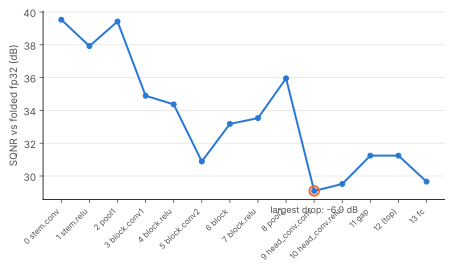

In [4]:
#| code-fold: true
#| code-summary: Plotting code
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(range(len(scores)), scores, color=BLUE, lw=2, marker="o", ms=5)
ax.scatter([worst], [scores[worst]], s=90, facecolors="none", edgecolors=ORANGE, linewidths=2, zorder=3)
ax.annotate(f"largest drop: {drops[worst - 1]:+.1f} dB", (worst, scores[worst]), xytext=(0, -22),
            textcoords="offset points", ha="center", color=MUTED, fontsize=9)
ax.set_xticks(range(len(scores)), [f"{i} {n}" for i, n in enumerate(names)], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("SQNR vs folded fp32 (dB)", color=MUTED)
ax.grid(axis="y", color="#e6e5e1", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [5]:
table([[i, m, f"{s:.1f}", "—" if i == 0 else f"{s - scores[i - 1]:+.1f}"] for i, (m, s) in enumerate(result)],
      ["#", "module", "SQNR (dB)", "vs previous"])

#,module,SQNR (dB),vs previous
0,stem.conv,39.5,—
1,stem.relu,37.9,-1.6
2,pool1,39.4,+1.5
3,block.conv1,34.9,-4.5
4,block.relu,34.4,-0.5
5,block.conv2,30.9,-3.5
6,block,33.2,+2.3
7,block.relu,33.5,+0.4
8,pool2,36.0,+2.4
9,head_conv.conv,29.1,-6.9


The number at each location is the SQNR of "the quantized graph's output at this node" against "the reference graph's output at the same node".
The same input runs from the start to here, so it accumulates the error of all earlier layers. `(top)` is a node that belongs to no submodule (`flatten`).

## B. How to Read It

In [6]:
ups = sum(d > 0 for d in drops)
print(f"Overall: from {scores[0]:.1f} dB down to {scores[-1]:.1f} dB; {ups} of {len(drops)} steps go up")
print(f"Largest drop vs previous: location {worst} ({names[worst]}, {drops[worst - 1]:+.1f} dB)")
assert scores[-1] < scores[0] and ups > 0

Overall: from 39.5 dB down to 29.7 dB; 6 of 13 steps go up
Largest drop vs previous: location 9 (head_conv.conv, -6.9 dB)


- **The trend goes down toward the end**: the closer to the output, the more quantization error has accumulated. Direct evidence of accumulation is in section D of M05-4: quantize only the first k modules, and the larger k is, the lower the overall SQNR.
- **But it is not a steady layer-by-layer decline**: several steps go up. Each location has a different signal magnitude and distribution, so the ratio of error to signal (SQNR) is not necessarily monotonic. This is an inference; it is not broken down item by item here.
- **Each step's drop mixes two things**: this layer's own quantization error, and the error passed down from before (which this layer may amplify, an inference).
  The location with the largest drop is a clue, but M05-4 will show that keeping it in fp32 is not necessarily the most useful; what affects the overall SQNR most is the final `fc`.

So layerwise SQNR is for **narrowing down**: first look at the overall SQNR to tell whether there is a problem, then use layerwise SQNR to find candidates, and finally confirm by experiment (M05-4).

## C. Which Graph to Use as the Reference

Intuitively you would take the original exported graph as the reference. Let's try it:

In [7]:
gm = export_module(model, example_inputs())
from_export = layerwise_sqnr(gm, copy.deepcopy(quant), x)
print(f"reference = graph after prepare:   {len(result)} locations matched")
print(f"reference = original exported graph: {len(from_export)} locations matched")
assert len(result) > 0 and len(from_export) == 0

reference = graph after prepare:   14 locations matched
reference = original exported graph: 0 locations matched


On torchao 0.18, the original exported graph matches not a single location, and `compare_results` returns an empty result without raising an error.
An inference (the alignment details in the source are not traced here): the alignment relies on node provenance info processed by `prepare_pt2e`, and a graph that has not been through prepare has no such info.
Even if it matched, the original exported graph still has an unfolded BN, so the conv output is not the same op as in the quantized graph, and the low SQNR you would measure is a false alarm.
The graph "after prepare, before calibration" has neither problem: its ops are the same as the quantized graph, and the only difference is quantization.

## Summary

- The numeric debugger gives every location an SQNR that accumulates the error of all earlier layers; overall it goes down toward the end, but not monotonically.
- The location with the largest drop is a clue, not a conclusion, and has to be confirmed by experiment (M05-4).
- Use the copy "after prepare, before calibration" as the reference graph; the original exported graph matches no location.